<a href="https://colab.research.google.com/github/ambre-bissi/ESG-Portfolio-Optimizer/blob/main/Notebooks/02_risk_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Risk Analysis**
Objectifs :

* Calculer les indicateurs de risque
* Comparer les actions
* Préparer la construction du portefeuille

### Objectifs en questions :


**Quel est le profil risque/rendement des actions de notre univers d'investissement ?**


* quelles actions sont les plus risquées
* quelles actions rapportent le plus
* quelles actions présentent le meilleur compromis risque/rendement
* quelles sont les corrélations entre elles

In [21]:
!git clone https://github.com/ambre-bissi/ESG-Portfolio-Optimizer.git
%cd /content/ESG-Portfolio-Optimizer

Cloning into 'ESG-Portfolio-Optimizer'...
remote: Enumerating objects: 87, done.
remote: Counting objects: 100% (87/87), done.
remote: Compressing objects: 100% (81/81), done.
remote: Total 87 (delta 33), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (87/87), 154.54 KiB | 4.42 MiB/s, done.
Resolving deltas: 100% (33/33), done.
/content/ESG-Portfolio-Optimizer


In [22]:
from src.risk_metrics import (
    annual_return,
    annual_volatility,
    sharpe_ratio,
    max_drawdown,
    value_at_risk,
    expected_shortfall,
)

In [23]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

#from src.risk_metrics import *

In [24]:
p0 = pd.read_csv("Data/merged.csv")
p0.head()

,ticker,name,currency,exchange,industry,logo,weburl,environment_grade,environment_level,social_grade,...,social_score,governance_score,total_score,last_processing_date,total_grade,total_level,cik,z_score,rendement_moyen,volatilite
0,DIS,Walt Disney Co,USD,"NEW YORK STOCK EXCHANGE, INC.",Media,https://static.finnhub.io/logo/ef50b4a2b263c84...,https://thewaltdisneycompany.com/,A,High,BB,...,316,321,1147,19-04-2022,BBB,High,1744489,0.783390,-0.000168,0.018357
1,GM,General Motors Co,USD,"NEW YORK STOCK EXCHANGE, INC.",Automobiles,https://static.finnhub.io/logo/9253db78-80c9-1...,https://www.gm.com/,A,High,BB,...,303,255,1068,17-04-2022,BBB,High,1467858,0.422000,0.000858,0.023461
2,GWW,WW Grainger Inc,USD,"NEW YORK STOCK EXCHANGE, INC.",Trading Companies and Distributors,https://static.finnhub.io/logo/f153dcda-80eb-1...,https://www.grainger.com/,B,Medium,BB,...,385,240,880,19-04-2022,BB,Medium,277135,-0.438017,0.000913,0.015409
3,MHK,Mohawk Industries Inc,USD,"NEW YORK STOCK EXCHANGE, INC.",Consumer products,https://static.finnhub.io/logo/26868a62-80ec-1...,https://mohawkind.com/,A,High,B,...,298,303,1171,18-04-2022,BBB,High,851968,0.893180,0.000121,0.024428
4,LYV,Live Nation Entertainment Inc,USD,"NEW YORK STOCK EXCHANGE, INC.",Media,https://static.finnhub.io/logo/1cd144d2-80ec-1...,https://www.livenationentertainment.com/,BBB,High,BB,...,310,250,1052,18-04-2022,BBB,High,1335258,0.348807,0.000810,0.022397


Calcul des rendements
Rt ​= (Pt/​Pt​​−1) - 1

attention, dans notre fichier merged on a pas gardé les prix, il faut donc réimporter yfinance

In [25]:
import yfinance as yf

tickers = p0["ticker"]

prices = yf.download(tickers.tolist(), start="2021-01-01", end="2026-01-01", auto_adjust=True)["Close"]

[*********************100%***********************]  569 of 569 completed
ERROR:yfinance:
2 Failed downloads:
ERROR:yfinance:['AEI']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2026-01-01)')
ERROR:yfinance:['ACHV']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2026-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1767243600")')


In [26]:
prices.head()

Ticker,A,AACG,AAL,AAME,AAOI,AAON,AAP,AAPL,AATC,ABBV,...,YSG,YUM,YUMC,ZBH,ZBRA,ZEPP,ZION,ZTS,ZWS,ZYME
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009117,1.18,15.13,2.043612,8.76,41.937099,137.724854,125.537155,2.065668,84.219139,...,83.150002,95.016190,53.039291,141.603363,378.130005,49.327869,35.169937,152.951965,17.683165,48.970001
2021-01-05,114.941254,1.23,15.43,2.482893,8.91,42.410194,137.576065,127.089241,2.061016,85.090004,...,84.650002,95.025162,54.117748,144.053436,380.570007,51.571800,35.727020,154.017883,18.190086,50.880001
2021-01-06,118.093224,1.22,15.52,2.196406,9.58,44.639576,145.524078,122.811203,2.349465,84.354965,...,89.449997,95.545952,53.941105,148.158371,394.820007,52.306885,39.741295,156.280518,19.003010,51.669998
2021-01-07,121.235603,1.27,15.38,2.253703,9.64,45.670017,146.767059,127.001945,2.079625,85.257797,...,85.750000,94.818649,53.978291,147.280045,409.100006,51.300983,40.953766,156.140289,20.112774,53.540001
2021-01-08,122.100456,1.24,15.13,2.301451,10.19,44.918255,148.859116,128.098099,2.098236,85.705208,...,90.550003,96.210388,55.661037,146.956497,405.470001,51.610493,39.913334,157.178101,20.295443,56.810001


In [27]:
returns = prices.pct_change()

returns = returns.drop(columns=["AEI", "ACHV"])
#colonnes dont le téléchargement a échoué

/tmp/ipykernel_1197/1270712245.py:1: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = prices.pct_change()


In [28]:
returns.describe()

Ticker,A,AAL,AAME,AAOI,AAON,AAP,AAPL,AATC,ABBV,ABCB,...,YRD,YSG,YUM,YUMC,ZBH,ZBRA,ZEPP,ZTS,ZWS,ZYME
count,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,...,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000,1254.000000
mean,0.000296,0.000466,0.001415,0.003371,0.000817,-0.000509,0.000767,0.001288,0.000874,0.000806,...,0.001399,-0.000865,0.000440,0.000175,-0.000234,-0.000046,0.001042,-0.000032,0.000975,0.000315
std,0.017942,0.030308,0.052984,0.069029,0.026060,0.032281,0.017552,0.035425,0.014137,0.021140,...,0.050995,0.055616,0.012710,0.023296,0.016316,0.024647,0.057672,0.016738,0.020600,0.040239
min,-0.096645,-0.144784,-0.204280,-0.321759,-0.229171,-0.350357,-0.092456,-0.239611,-0.125664,-0.125088,...,-0.204413,-0.395161,-0.084360,-0.155095,-0.151483,-0.172717,-0.207279,-0.137790,-0.110315,-0.288490
25%,-0.009536,-0.016573,-0.019756,-0.030523,-0.012081,-0.013994,-0.007934,-0.009958,-0.006121,-0.011277,...,-0.024513,-0.030464,-0.006614,-0.011466,-0.008492,-0.012845,-0.028865,-0.008774,-0.010367,-0.020174
50%,0.000387,0.000000,0.000000,-0.001603,0.000725,-0.000262,0.001096,0.000000,0.001149,-0.000305,...,-0.002669,0.000000,0.000539,-0.000256,-0.000476,0.000256,-0.003025,0.000247,0.000633,0.000000
75%,0.010368,0.014872,0.019980,0.032258,0.013401,0.013453,0.009843,0.010958,0.008782,0.012324,...,0.022624,0.025502,0.007660,0.011143,0.008187,0.013152,0.021277,0.009425,0.011827,0.019786
max,0.087208,0.226020,1.175732,0.670713,0.160705,0.570425,0.153288,0.734663,0.063605,0.136967,...,0.546099,0.246575,0.097219,0.148468,0.079868,0.141566,0.694581,0.070887,0.122028,0.290497


rendement moyen ?
rendement max ?
rendement min ?

### Rendement annualisé

In [29]:
annual_returns = annual_return(returns)

annual_returns.sort_values(ascending=False)

,0
Ticker,
CLVR,6832.380489
AFIB,21.060113
MTC,1.985652
AEHR,0.945798
AAOI,0.849485
...,...
HCAT,-0.370113
MYPS,-0.374524
AKTX,-0.542968


Il y a un énorme écart entre le 1er Clever Leaves Holdings Inc. (CLVR) et le 2e Acutus Medical, Inc. (AFIB) puis le 2e et le 3e MMTec, Inc. (MTC). On les retire, /!\ réfléchir à la cause possible


In [44]:
#returns = returns.drop(columns=["CLVR", "AFIB"])

annual_returns = annual_return(returns)

<Axes: xlabel='Ticker'>

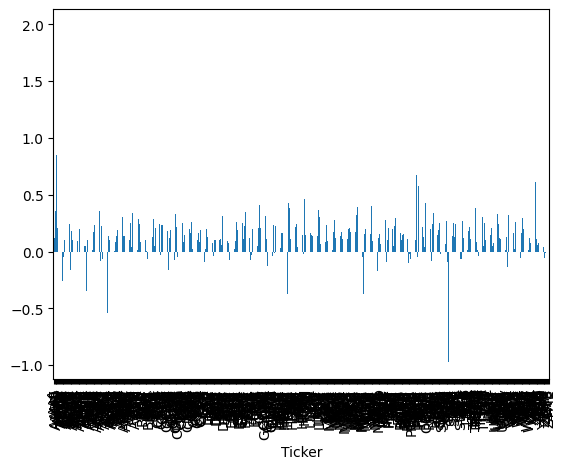

In [46]:
annual_returns.plot.bar()

quelles actions ont été les plus performantes ? (AEHR sur ce graphique, mais le classement nous en apprend plus que le graphique)

(graphique pas intéractif, peu pratique -> faire sur PowerBI les graphiques importants ?)

### Volatilité annualisée

In [47]:
vols = annual_volatility(returns)

<Axes: xlabel='Ticker'>

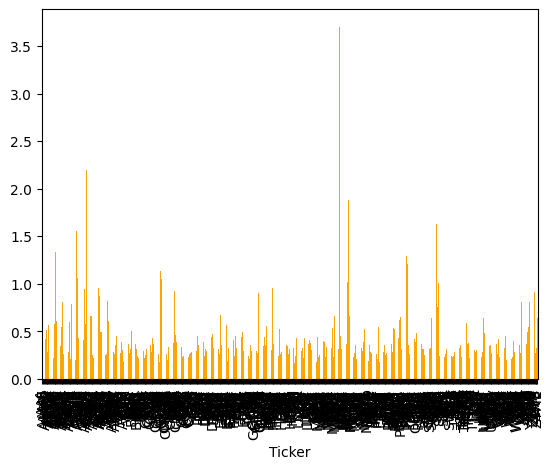

In [58]:
vols.plot.bar(color="orange")

#vols[310:360].plot.bar(color="orange")

quelles actions sont les plus risquées ? MTC (3e rdt annuel) suivi de MVST

### Sharpe Ratio
(métrique très connue)

In [53]:
sharpe = sharpe_ratio(returns, risk_free_rate=0.02)

<Axes: xlabel='Ticker'>

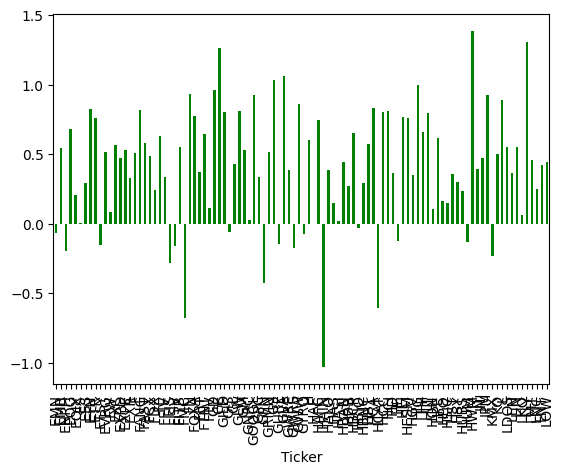

In [57]:
sharpe.plot.bar(color="green")

#sharpe[200:300].plot.bar(color="green")

quelles actions rémunèrent le mieux le risque pris ? HWM, pas dans le top des rdt donc devait êre peu risquée ?

### Corrélations

In [35]:
corr = returns.corr()

<Axes: xlabel='Ticker', ylabel='Ticker'>

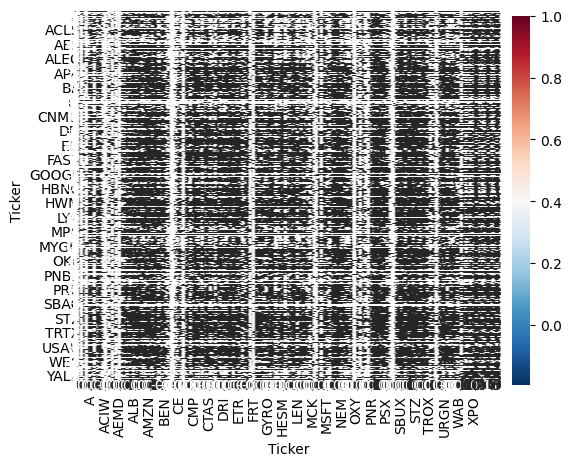

In [36]:
#sns.heatmap(corr,annot=True,cmap="RdBu_r")

#choisir les tickers interessants pour que la heatmp soit
#lisible et ne prenne pas trop de tps à charger

""" exemple : Airbus et Safran sont-ils corrélés ?
            LVMH apporte-t-elle de la diversification ?"""

Résultats des corrélations :

### Distribution des rendements

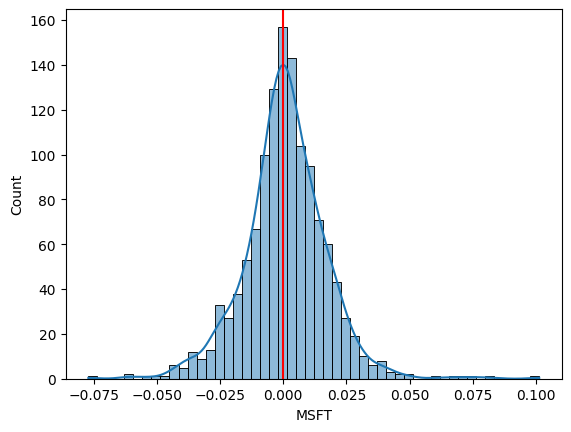

In [61]:
#pour microsoft ici
sns.histplot(
    returns["MSFT"],
    bins=50,
    kde=True
)

#affichage d'une barre verticale en 0
plt.axvline(0, color="red")




* moyenne -> nulle, tout va bien
* dispersion -> +/- 0.05
* asymétrie -> non, normal (cloche)

### Maximum Drawdown

<Axes: >

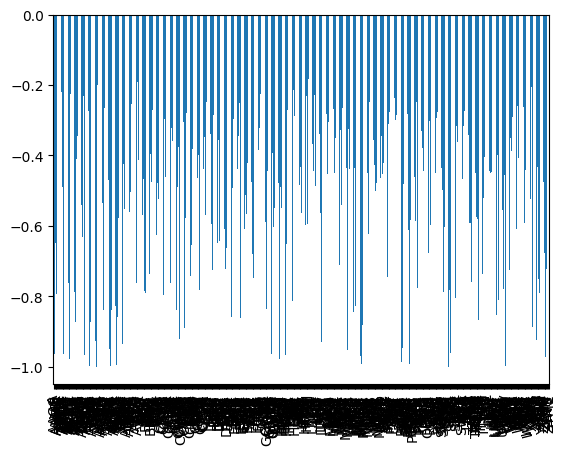

In [38]:
drawdowns = {}

for col in prices.columns:

    drawdowns[col] = max_drawdown(prices[col])

pd.Series(drawdowns).plot.bar()

quelle a été la pire perte historique ? -> beaucoup approche les -1 (à la même période ?)

### Value at Risk

In [64]:
vars_95 = returns.apply(value_at_risk)

print(vars_95) #ne fonctionne pas, revoir la formule

Ticker
A      NaN
AAL    NaN
AAME   NaN
AAOI   NaN
AAON   NaN
        ..
ZBRA   NaN
ZEPP   NaN
ZTS    NaN
ZWS    NaN
ZYME   NaN
Length: 562, dtype: float64


Interprétation : 95 % du temps la perte quotidienne est inférieure à 2.8 % (si le résultat est -2.8%).

### Expected Shortfall

In [65]:
es_95 = returns.apply(expected_shortfall)

print(es_95)

Ticker
A      NaN
AAL    NaN
AAME   NaN
AAOI   NaN
AAON   NaN
        ..
ZBRA   NaN
ZEPP   NaN
ZTS    NaN
ZWS    NaN
ZYME   NaN
Length: 562, dtype: float64


Lors des pires journées, quelle est la perte moyenne ?

### Risk-Return Scatter Plot

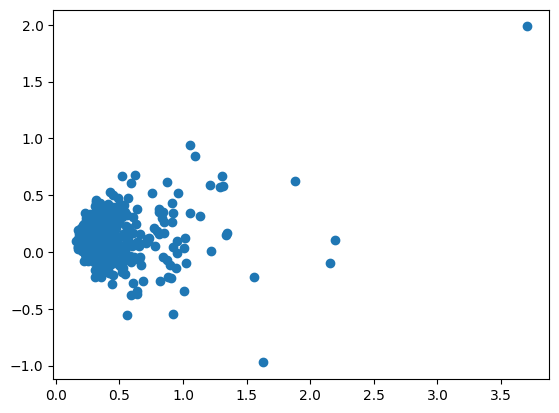

In [66]:
plt.scatter(
    vols,
    annual_returns
)

#x = volatilité
#y = rendement

Text(0, 0.5, 'Rendement annuel')

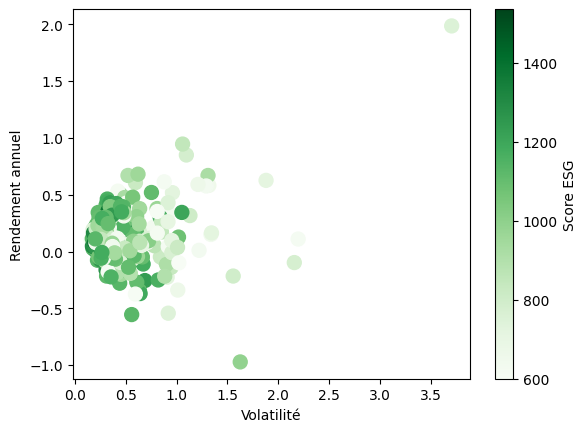

In [68]:
# On aligne les scores ESG sur les tickers présents dans vols et annual_returns
esg_aligned = p0.set_index("ticker").loc[vols.index]["total_score"]

plt.scatter(
    vols,
    annual_returns,
    c=esg_aligned,
    cmap="Greens",
    s=100
)
plt.colorbar(label="Score ESG")
plt.xlabel("Volatilité")
plt.ylabel("Rendement annuel")

### Conclusion
Airbus possède le rendement annualisé le plus élevé.

Sanofi présente la volatilité la plus faible.

L'Oréal possède le meilleur Sharpe Ratio.

Le secteur santé apparaît le plus défensif.

Certaines actions offrent simultanément un bon score ESG et un profil de risque attractif.

Ces résultats serviront pour construire les portefeuilles du notebook  suivant (03_portfolio_construction.ipynb).